# Optimización de Tiempos de Atención en Urgencias mediante Modelos Predictivos de Machine Learning

### ¡SIGU - Sistema Inteligente de Gestion de Urgencias!

Se descargó el dataset en un csv para poder hacer el experimento reproducible del sitio oficial de datos abiertos

Informacion del Dataset: Clasificación en Triage Urgencias Salud y Protección Social\
Registros de usuarios que fueron atendidos y clasificados en triage en los servicios de urgencias de las Instituciones prestadoras de servicios de salud de la Empresa Social del Estado Pasto Salud. Es un indicador de Calidad de la resolución 256

Enlace: https://www.datos.gov.co/Salud-y-Protecci-n-Social/Clasificaci-n-en-Triage-Urgencias/vt5n-eu2r/about_data





In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [74]:
data = pd.read_csv('C:\\Users\\soporte.sistemas\\RepoLocal\\Unicafam\\Project_Analitica_II\\data\\Clasificación_en_Triage_Urgencias_20261003.csv', encoding='latin-1')
data.head() # Mostramos las primeras filas del dataset

,CodAdminis,Nom_Admini,Fecha_Ing,Hora_Ingre,Fecha_Atencion,Hora_Atencion,Triage,Ips,Red
0,ESS118,EMSSANAR S.A.S,2020 Jan 23 08:29:02 AM,1900 Jan 01 08:29:00 AM,2020 Jan 23 08:36:00 AM,1900 Jan 01 08:36:00 AM,III,HOSPITAL LOCAL CIVIL,RED NORTE
1,ESS118,EMSSANAR S.A.S,2020 Jan 23 08:29:02 AM,1900 Jan 01 08:29:00 AM,2020 Jan 23 08:36:00 AM,1900 Jan 01 08:36:00 AM,III,HOSPITAL LOCAL CIVIL,RED NORTE
2,ESS118,EMSSANAR S.A.S,2020 Jan 14 09:27:46 AM,1900 Jan 01 09:27:00 AM,2020 Jan 14 10:18:00 AM,1900 Jan 01 10:18:00 AM,III,HOSPITAL LOCAL CIVIL,RED NORTE
3,ESS118,EMSSANAR S.A.S,2020 Feb 29 09:01:31 AM,1900 Jan 01 09:01:00 AM,2020 Feb 29 09:11:00 AM,1900 Jan 01 09:11:00 AM,III,CENTRO HOSPITAL LA ROSA,RED SUR
4,ESS118,EMSSANAR S.A.S,2020 Feb 09 05:26:00 PM,1900 Jan 01 05:26:00 PM,2020 Feb 09 05:50:00 PM,1900 Jan 01 05:50:00 PM,III,HOSPITAL LOCAL CIVIL,RED NORTE


In [75]:
data.shape # Validamos las dimensiones del dataset

(89453, 9)

In [76]:
data.info() # Información general del dataset

<class 'pandas.DataFrame'>
RangeIndex: 89453 entries, 0 to 89452
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   CodAdminis      89452 non-null  str  
 1   Nom_Admini      89452 non-null  str  
 2   Fecha_Ing       89453 non-null  str  
 3   Hora_Ingre      89453 non-null  str  
 4   Fecha_Atencion  89453 non-null  str  
 5   Hora_Atencion   89453 non-null  str  
 6   Triage          89453 non-null  str  
 7   Ips             89453 non-null  str  
 8   Red             89453 non-null  str  
dtypes: str(9)
memory usage: 6.1 MB


In [77]:
# Verificamos si hay filas duplicadas en el dataset
#data.columns = data.columns.str.strip().str.lower()
data.duplicated().sum() 

np.int64(9932)

In [78]:
# Eliminamos las filas duplicadas del dataset

data = data.drop_duplicates().copy()
data.duplicated().sum()  # Verificamos nuevamente si hay filas duplicadas

np.int64(0)

In [79]:
data.shape # Validamos las dimensiones del dataset después de eliminar duplicados

(79521, 9)

In [80]:
# Convertimos fechas completas (ignorando Hora_Ingre y Hora_Atencion con año 1900)

formato_fecha = "%Y %b %d %I:%M:%S %p"

data['dt_ingreso'] = pd.to_datetime(data['Fecha_Ing'], format=formato_fecha, errors='coerce')
data['dt_atencion'] = pd.to_datetime(data['Fecha_Atencion'], format=formato_fecha, errors='coerce')

In [81]:
# Eliminar filas sin fecha valida

data = data.dropna(subset=['dt_ingreso', 'dt_atencion']).copy()

In [82]:
# Calculamos la variable continua de espera en minutos entre la fecha de ingreso y la fecha de atención
data['tiempo_espera_min'] = (data['dt_atencion'] - data['dt_ingreso']).dt.total_seconds() / 60.0

In [83]:
# Agregar mas variables de tiempo para análisis adicionales

data['hora_dia'] = data['dt_ingreso'].dt.hour
data['dia_semana'] = data['dt_ingreso'].dt.day_name()
data['anio_mes'] = data['dt_ingreso'].dt.to_period("M").astype(str)

def asignar_franja(hora):
    if 6 <= hora < 12:
        return "Mañana (06:00 - 11:59)"
    elif 12 <= hora < 18:
        return "Tarde (12:00 - 17:59)"
    elif 18 <= hora < 24:
        return "Noche (18:00 - 23:59)"
    else:
        return "Madrugada (00:00 - 05:59)"

data['franja_horaria'] = data['hora_dia'].apply(asignar_franja)

In [84]:
data.head() # Mostramos las primeras filas del dataset después de los cambios

,CodAdminis,Nom_Admini,Fecha_Ing,Hora_Ingre,Fecha_Atencion,Hora_Atencion,Triage,Ips,Red,dt_ingreso,dt_atencion,tiempo_espera_min,hora_dia,dia_semana,anio_mes,franja_horaria
0,ESS118,EMSSANAR S.A.S,2020 Jan 23 08:29:02 AM,1900 Jan 01 08:29:00 AM,2020 Jan 23 08:36:00 AM,1900 Jan 01 08:36:00 AM,III,HOSPITAL LOCAL CIVIL,RED NORTE,2020-01-23 08:29:02,2020-01-23 08:36:00,6.966667,8,Thursday,2020-01,Mañana (06:00 - 11:59)
2,ESS118,EMSSANAR S.A.S,2020 Jan 14 09:27:46 AM,1900 Jan 01 09:27:00 AM,2020 Jan 14 10:18:00 AM,1900 Jan 01 10:18:00 AM,III,HOSPITAL LOCAL CIVIL,RED NORTE,2020-01-14 09:27:46,2020-01-14 10:18:00,50.233333,9,Tuesday,2020-01,Mañana (06:00 - 11:59)
3,ESS118,EMSSANAR S.A.S,2020 Feb 29 09:01:31 AM,1900 Jan 01 09:01:00 AM,2020 Feb 29 09:11:00 AM,1900 Jan 01 09:11:00 AM,III,CENTRO HOSPITAL LA ROSA,RED SUR,2020-02-29 09:01:31,2020-02-29 09:11:00,9.483333,9,Saturday,2020-02,Mañana (06:00 - 11:59)
4,ESS118,EMSSANAR S.A.S,2020 Feb 09 05:26:00 PM,1900 Jan 01 05:26:00 PM,2020 Feb 09 05:50:00 PM,1900 Jan 01 05:50:00 PM,III,HOSPITAL LOCAL CIVIL,RED NORTE,2020-02-09 17:26:00,2020-02-09 17:50:00,24.000000,17,Sunday,2020-02,Tarde (12:00 - 17:59)
5,ESS118,EMSSANAR S.A.S,2020 Jan 26 04:31:55 PM,1900 Jan 01 04:31:00 PM,2020 Jan 26 04:36:00 PM,1900 Jan 01 04:36:00 PM,III,CS SAN VICENTE,RED OCCIDENTE,2020-01-26 16:31:55,2020-01-26 16:36:00,4.083333,16,Sunday,2020-01,Tarde (12:00 - 17:59)


In [85]:
# Ordenamos cronologicamente y calculamos la variable tiempo entre llegadas

data = data.sort_values(['Ips','dt_ingreso']).reset_index(drop=True)
data['tiempo_entre_llegadas_min'] = (data.groupby('Ips')['dt_ingreso'].diff().dt.total_seconds() /60.0)

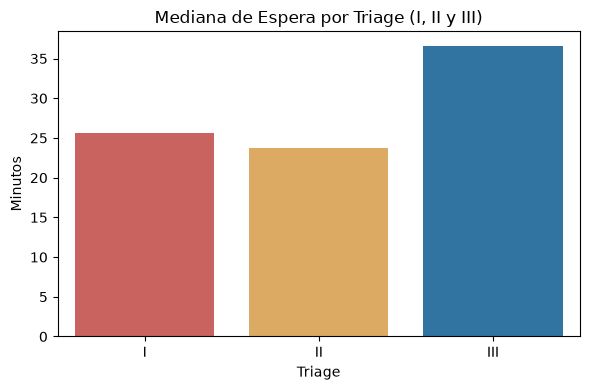

In [86]:
df = data.copy()
df_t123 = df[df["Triage"].isin(["I", "II", "III"])]
colores = {"I": "#d9534f", "II": "#f0ad4e", "III": "#1f77b4"}

plt.figure(figsize=(6, 4))
ax = sns.barplot(
    data=df_t123, x="Triage", y="tiempo_espera_min",
    order=["I", "II", "III"], estimator="median", errorbar=None,
    hue="Triage", dodge=False, palette=colores
)
if ax.get_legend():
    ax.get_legend().remove()

plt.title("Mediana de Espera por Triage (I, II y III)")
plt.ylabel("Minutos")
plt.tight_layout()
plt.show()

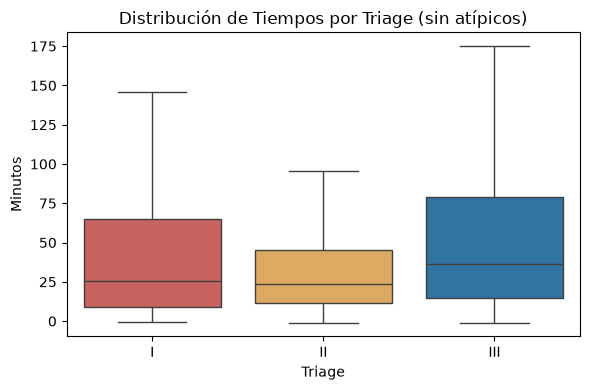

In [87]:
plt.figure(figsize=(6, 4))
ax = sns.boxplot(
    data=df_t123, x="Triage", y="tiempo_espera_min",
    order=["I", "II", "III"], showfliers=False,
    hue="Triage", dodge=False, palette=colores
)
if ax.get_legend():
    ax.get_legend().remove()

plt.title("Distribución de Tiempos por Triage (sin atípicos)")
plt.ylabel("Minutos")
plt.tight_layout()
plt.show()

In [88]:
# Seleccionamos columnas finales limpias

columnas_finales = [
    "dt_ingreso", "dt_atencion", "anio_mes", "dia_semana", "hora_dia",
    "franja_horaria", "Triage", "Ips", "Red", "Nom_Admini",
    "tiempo_espera_min", "tiempo_entre_llegadas_min"
]

data_limpio = data[columnas_finales]
data_limpio.head()

,dt_ingreso,dt_atencion,anio_mes,dia_semana,hora_dia,franja_horaria,Triage,Ips,Red,Nom_Admini,tiempo_espera_min,tiempo_entre_llegadas_min
0,2020-01-01 00:35:06,2020-01-01 00:38:00,2020-01,Wednesday,0,Madrugada (00:00 - 05:59),II,CENTRO HOSPITAL LA ROSA,RED SUR,EMSSANAR S.A.S,2.900000,NaN
1,2020-01-01 03:28:37,2020-01-01 03:45:00,2020-01,Wednesday,3,Madrugada (00:00 - 05:59),III,CENTRO HOSPITAL LA ROSA,RED SUR,EMSSANAR S.A.S,16.383333,173.516667
2,2020-01-01 04:14:59,2020-01-01 04:38:00,2020-01,Wednesday,4,Madrugada (00:00 - 05:59),III,CENTRO HOSPITAL LA ROSA,RED SUR,COMPAÃÃA MUNDIAL DE SEGUROS S.A.,23.016667,46.366667
3,2020-01-01 04:30:01,2020-01-01 04:47:00,2020-01,Wednesday,4,Madrugada (00:00 - 05:59),III,CENTRO HOSPITAL LA ROSA,RED SUR,EMSSANAR S.A.S,16.983333,15.033333
4,2020-01-01 04:41:38,2020-01-01 05:08:00,2020-01,Wednesday,4,Madrugada (00:00 - 05:59),III,CENTRO HOSPITAL LA ROSA,RED SUR,EMSSANAR S.A.S,26.366667,11.616667


In [89]:
print(f"Registros limpios guardados: {len(data_limpio):,}")
print(f"Tiempo de espera promedio: {data_limpio['tiempo_espera_min'].mean():.2f} min")
print(f"Mediana de espera: {data_limpio['tiempo_espera_min'].median():.2f} min")

Registros limpios guardados: 79,521
Tiempo de espera promedio: 57.02 min
Mediana de espera: 38.60 min


In [90]:
data_limpio.describe()

,dt_ingreso,dt_atencion,hora_dia,tiempo_espera_min,tiempo_entre_llegadas_min
count,79521,79521,79521.000000,79521.000000,79513.000000
mean,2021-11-15 20:06:02.562581,2021-11-15 21:03:03.826159,12.979779,57.021060,82.651718
min,2020-01-01 00:20:32,2020-01-01 00:37:00,0.000000,-0.983333,0.000000
25%,2021-07-23 14:43:57,2021-07-23 15:23:00,9.000000,15.850000,6.000000
50%,2022-01-23 00:30:05,2022-01-23 00:37:00,13.000000,38.600000,13.116667
75%,2022-06-26 08:40:00,2022-06-26 08:50:00,17.000000,83.650000,33.150000
max,2022-09-29 23:45:00,2022-09-30 01:11:00,23.000000,360.000000,724111.616667
std,NaN,NaN,5.313589,53.953481,4968.068411


In [91]:
# Eliminar los 172 desfases negativos de reloj (< 0 min)
data_limpio = data_limpio[data_limpio["tiempo_espera_min"] >= 0].copy()

# Rellenar el único nulo en Nom_Admini
data_limpio["Nom_Admini"] = data_limpio["Nom_Admini"].fillna("NO REPORTADA")

# Recalcular tiempo_entre_llegadas_min dentro de cada (Ips, anio_mes)
data_limpio = data_limpio.sort_values(["Ips", "dt_ingreso"]).reset_index(drop=True)
tel_mes = data_limpio.groupby(["Ips", "anio_mes"])["dt_ingreso"].diff().dt.total_seconds() / 60.0

# Descartar saltos mayores a 24 h (1440 min) y rellenar bordes con la mediana de cada sede
tel_sin_saltos = tel_mes.where(tel_mes <= 1440, np.nan)
mediana_por_ips = tel_sin_saltos.groupby(data_limpio["Ips"]).transform("median").fillna(tel_sin_saltos.median())

data_limpio["tiempo_entre_llegadas_min"] = tel_sin_saltos.fillna(mediana_por_ips).round(2)
data_limpio["tiempo_espera_min"] = data_limpio["tiempo_espera_min"].round(2)

# Guardar el CSV final listo para backend.py y app.py
data_limpio.to_csv('C:\\Users\\soporte.sistemas\\RepoLocal\\Unicafam\\Project_Analitica_II\\SIGU\\urgencias_limpio.csv', encoding='latin-1')

In [92]:
data_limpio.shape

(79349, 12)

In [93]:
data_limpio.describe()

,dt_ingreso,dt_atencion,hora_dia,tiempo_espera_min,tiempo_entre_llegadas_min
count,79349,79349,79349.000000,79349.000000,79349.000000
mean,2021-11-16 02:20:01.737879,2021-11-16 03:17:10.468941,12.977769,57.145503,33.267325
min,2020-01-01 00:20:32,2020-01-01 00:37:00,0.000000,0.000000,0.000000
25%,2021-07-23 17:06:31,2021-07-23 18:18:00,9.000000,16.000000,6.000000
50%,2022-01-23 17:01:12,2022-01-23 18:14:00,13.000000,38.780000,13.050000
75%,2022-06-26 15:10:00,2022-06-26 16:07:00,17.000000,83.920000,33.000000
max,2022-09-29 23:45:00,2022-09-30 01:11:00,23.000000,360.000000,1426.030000
std,NaN,NaN,5.310511,53.945599,73.261841


In [94]:
data_limpio.head()

,dt_ingreso,dt_atencion,anio_mes,dia_semana,hora_dia,franja_horaria,Triage,Ips,Red,Nom_Admini,tiempo_espera_min,tiempo_entre_llegadas_min
0,2020-01-01 00:35:06,2020-01-01 00:38:00,2020-01,Wednesday,0,Madrugada (00:00 - 05:59),II,CENTRO HOSPITAL LA ROSA,RED SUR,EMSSANAR S.A.S,2.90,12.00
1,2020-01-01 03:28:37,2020-01-01 03:45:00,2020-01,Wednesday,3,Madrugada (00:00 - 05:59),III,CENTRO HOSPITAL LA ROSA,RED SUR,EMSSANAR S.A.S,16.38,173.52
2,2020-01-01 04:14:59,2020-01-01 04:38:00,2020-01,Wednesday,4,Madrugada (00:00 - 05:59),III,CENTRO HOSPITAL LA ROSA,RED SUR,COMPAÃÃA MUNDIAL DE SEGUROS S.A.,23.02,46.37
3,2020-01-01 04:30:01,2020-01-01 04:47:00,2020-01,Wednesday,4,Madrugada (00:00 - 05:59),III,CENTRO HOSPITAL LA ROSA,RED SUR,EMSSANAR S.A.S,16.98,15.03
4,2020-01-01 04:41:38,2020-01-01 05:08:00,2020-01,Wednesday,4,Madrugada (00:00 - 05:59),III,CENTRO HOSPITAL LA ROSA,RED SUR,EMSSANAR S.A.S,26.37,11.62


### 1. Variable Objetivo (tiempo_espera_min): Alta asimetría positiva
Definición y naturaleza: Es una variable aleatoria continua ($X \ge 0$) que mide los minutos transcurridos desde la admisión/triage (dt_ingreso) hasta el inicio de la atención médica (dt_atencion).

Tendencia central vs. dispersión: Presenta una media de 57.15 min ($\sigma = 53.95$ min), frente a una mediana de 38.78 min y una moda de 10.00 min, con un rango intercuartílico ($\text{IQR}$) de 67.92 min ($Q_1 = 16.00$ min, $Q_3 = 83.92$ min).

Conclusión operativa: El hecho de que la media sea un 47.4% superior a la mediana y el coeficiente de asimetría sea de 1.38 demuestra que el proceso tiene una cola larga hacia la derecha: la mitad de los pacientes son atendidos en menos de 39 minutos, pero un 35.58% supera el umbral crítico de 60 minutos (llegando hasta 360 min), arrastrando el promedio general. Por ello, la mediana es un indicador más fiel del servicio típico que el promedio.

### 2. Distribución de Probabilidad: Descarte de la Normalidad
Al contrastar las distribuciones teóricas propuestas en el anteproyecto sobre los tiempos de espera positivos:


| Distribución evaluada | Parámetros estimados | Criterio AIC (menor = mejor ajuste) | Probabilidad estimada P(X>60 min) | Diagnóstico frente al valor real (35.58%) |
| :--- | :--- | :--- | :--- | :--- |
| Normal | $\mu = 57.17$, $\sigma = 53.94$ | 857,741 | 47.91% | Se descarta: sobreestima el riesgo y asigna probabilidad a tiempos negativos. |
| Log-normal | $s = 1.18$, $\text{escala} = 33.49$ | 807,873 | 31.00% | Buen ajuste: captura correctamente la asimetría y la cola derecha de espera. |
| Exponencial | $\text{media} = 57.17$ min | 800,486 | 35.01% | Mejor ajuste global: reproduce con precisión la proporción real de demoras $>60$ min. |


### 3. Dinámica de Llegadas (Poisson) y Efecto de Cola Acumulada

Tasa de llegada ($\lambda$) no estacionaria: Las llegadas por hora no siguen una tasa constante a lo largo de las 24 horas (razón por la cual la prueba Chi-cuadrado rechaza un único modelo de Poisson global si no se filtra por franja). El 70.67% de la demanda total se concentra entre la Mañana (36.10%) y la Tarde (34.57%), mientras que la Madrugada apenas representa el 6.55%.

Cuello de botella vespertino: Aunque la mayor cantidad de ingresos ocurre en la mañana (mediana de espera de 32.87 min), la mayor congestión se sufre en la Tarde (mediana de 49.47 min, media de 66.50 min) y la Noche (mediana de 44.03 min). Esto evidencia un efecto de arrastre: los pacientes no evacuados al final de la mañana saturan el inicio del turno de la tarde.

Tiempo entre llegadas (Exponencial): Tiene una mediana de 13.05 min (media de 33.27 min), reflejando ráfagas de arribos consecutivos en horas pico que elevan el riesgo de saturación inmediata.

### 4. Segmentación Clínica (Triage) y Brecha por Sede (IPS)
* Cumplimiento de priorización clínica: El sistema filtra adecuadamente según la gravedad:
Triage II (3.02%): Tiene la atención más rápida (mediana 24.00 min, solo 16.92% supera la hora).

    * Triage I (0.21%): Mediana de 26.28 min (en urgencias vitales la atención clínica es inmediata y el registro en sistema suele digitarse tras estabilizar al paciente).

    * Triage III (88.23%): Es el núcleo operativo del servicio (mediana 36.77 min, 33.74% supera la hora).

    * Triage IV y V (8.54% conjunto): Absorben la mayor espera (medianas de 79.00 y 82.00 min; más del 61% espera más de una hora) al ceder prioridad a casos agudos.
* Foco geográfico de congestión: Tres instituciones concentran el 99.82% de las atenciones, con comportamientos muy distintos:

    1. Hospital Local Civil (36.67% de casos): Es el punto crítico de la red, con mediana de 72.00 min y 56.86% de pacientes esperando más de una hora.
    2. Centro Hospital La Rosa (31.81%): Desempeño intermedio, con mediana de 37.83 min (32.42% $>60$ min).
    3. CS San Vicente (31.34%): El más fluido de la red, con mediana de 20.05 min (solo 13.98% $>60$ min).

### 5. Síntesis para la Propuesta Operativa y Machine Learning
1. Justificación del modelo predictivo: La correlación positiva entre carga horaria y espera ($r > 0$, $p < 0.001$) confirma que la demanda impacta la demora, pero factores no lineales (hora del día, cola acumulada del turno previo, sede y nivel de triage) explican gran parte de la variabilidad. Por ello, un algoritmo basado en árboles como Random Forest es más adecuado que una recta simple para simular escenarios de dotación.

2. Recomendación de gestión: La redistribución de personal médico no debe ser uniforme; los resultados sustentan reforzar la dotación prioritariamente en el Hospital Local Civil y durante la franja de la Tarde (12:00 – 17:59) para descongestionar el arrastre matutino y reducir el porcentaje de pacientes en Triage III que superan los 60 minutos.  